In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})



findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


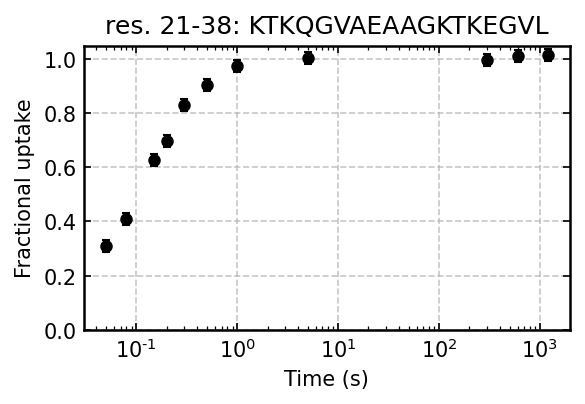

In [2]:
# load data
df = pd.read_csv('../../../HDXMS/EXP_DATA/aSyn.csv')
# keeps the order in which sequences first appear in df
peptide_sequences = pd.unique(df['Sequence'])
plot_idx = 10

pp = df[df['Sequence']==peptide_sequences[plot_idx]]

# plot

plt.figure(figsize = (4,2.8))

plt.errorbar(pp['Time (s)'], y=pp['Rel. Uptake'], yerr = pp['Rel. Uptake SD'], fmt='o', capsize = 2, color='black', markersize=5)
plt.xlabel('Time (s)')
plt.ylabel('Fractional uptake')
plt.ylim(0,1.05)
plt.title(f"res. {pp['Start'].iloc[0]}-{pp['End'].iloc[0]}: {peptide_sequences[plot_idx]}")
plt.xscale('log')
plt.tight_layout()
plt.savefig('HDX_example_plot_aSyn.png')

In [22]:
pp

,Start,End,Sequence,Protein,Modification,Time (s),Rel. Uptake,Rel. Uptake SD
110,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.05,0.307813,0.022209
111,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.08,0.407368,0.022209
112,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.15,0.625974,0.022209
113,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.20,0.698134,0.022209
114,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.30,0.831940,0.022209
115,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,0.50,0.904665,0.022209
116,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,1.00,0.975469,0.022209
117,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,5.00,1.003014,0.022209
118,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,300.00,0.995515,0.022209
119,21,38,KTKQGVAEAAGKTKEGVL,aSyn,NaN,600.00,1.009766,0.022209


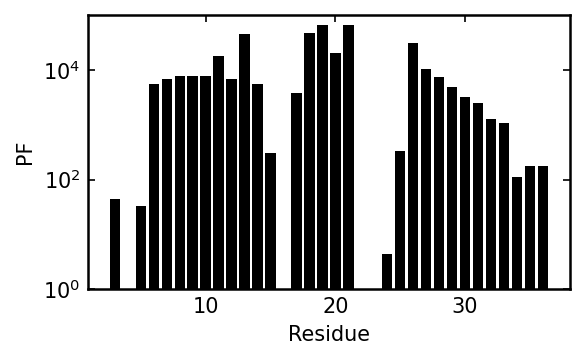

In [3]:
# example plot of PF vs res

df = pd.read_csv('../../EXP_DATA/PF_Nguyen_2018/HP36.csv')

plt.figure(figsize = (4,2.5))
plt.bar(df['Model_residue'], df['PF'], color = 'black')
plt.xlabel('Residue')
plt.ylabel('PF')
plt.yscale('log')
plt.grid(False)
plt.ylim(1e0,1e5)
plt.tight_layout()
plt.savefig('HP36_PFs_example.png')

min PF: 1.0
mean PF: 9.997748382393176


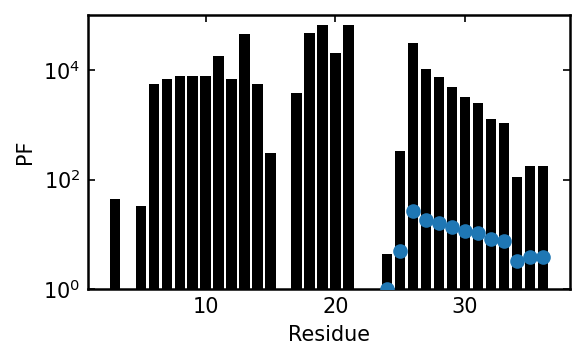

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

p_unf = 0.10  # 10%
target_pf = 1 / p_unf  # 10

df = pd.read_csv('../../EXP_DATA/PF_Nguyen_2018/HP36.csv')
pep_df = df[df['Model_residue'] > 22].copy()  # peptide of the c-terminal helix

# scale PFs in log space so:
# - minimum PF becomes 1
# - the N->C trend / relative variation on the log scale is preserved
# - mean PF is ~10
logpf = np.log10(pep_df['PF'].values)
logpf = logpf - np.min(logpf)   # set minimum to PF = 1

alphas = np.linspace(0, 10, 10000)
means = np.array([np.mean(10**(a * logpf)) for a in alphas])
alpha = alphas[np.argmin(np.abs(means - target_pf))]

pep_df['PF_scaled'] = 10**(alpha * logpf)

print('min PF:', np.min(pep_df['PF_scaled']))
print('mean PF:', np.mean(pep_df['PF_scaled']))

plt.figure(figsize=(4,2.5))
plt.bar(df['Model_residue'], df['PF'], color='black')
plt.scatter(pep_df['Model_residue'], pep_df['PF_scaled'], color='tab:blue', zorder=20)
plt.xlabel('Residue')
plt.ylabel('PF')
plt.yscale('log')
plt.grid(False)
plt.ylim(1e0,1e5)
plt.tight_layout()
plt.savefig(f'HP36_PFs_example_cterm_unf_{p_unf}.png')


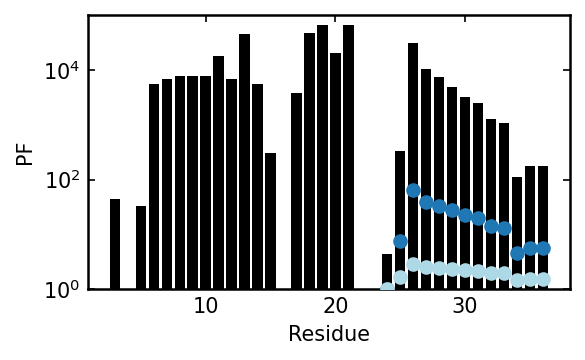

In [52]:


p_unf = 0.05  # 5%
target_pf = 1 / p_unf  
p_unf2 = 0.50  # 50%
target_pf2 = 1 / p_unf2  

df = pd.read_csv('../../EXP_DATA/PF_Nguyen_2018/HP36.csv')
pep_df = df[df['Model_residue'] > 22].copy()  # peptide of the c-terminal helix
pep_df2 = df[df['Model_residue'] > 22].copy()  # peptide of the c-terminal helix

# scale PFs in log space so:
# - minimum PF becomes 1
# - the N->C trend / relative variation on the log scale is preserved
# - mean PF is ~10
logpf = np.log10(pep_df['PF'].values)
logpf = logpf - np.min(logpf)   # set minimum to PF = 1
logpf2 = np.log10(pep_df2['PF'].values)
logpf2 = logpf2 - np.min(logpf2)   # set minimum to PF = 1

alphas = np.linspace(0, 10, 10000)
means = np.array([np.mean(10**(a * logpf)) for a in alphas])
alpha = alphas[np.argmin(np.abs(means - target_pf))]
alphas2 = np.linspace(0, 10, 10000)
means2 = np.array([np.mean(10**(a * logpf2)) for a in alphas2])
alpha2 = alphas2[np.argmin(np.abs(means2 - target_pf2))]

pep_df['PF_scaled'] = 10**(alpha * logpf)
pep_df2['PF_scaled'] = 10**(alpha2 * logpf2)

plt.figure(figsize=(4,2.5))
plt.bar(df['Model_residue'], df['PF'], color='black')
plt.scatter(pep_df['Model_residue'], pep_df['PF_scaled'], color='tab:blue', zorder=20)
plt.scatter(pep_df2['Model_residue'], pep_df2['PF_scaled'], color='lightblue', zorder=20)
plt.xlabel('Residue')
plt.ylabel('PF')
plt.yscale('log')
plt.grid(False)
plt.ylim(1e0,1e5)
plt.tight_layout()
plt.savefig(f'HP36_PFs_example_cterm_unf_two_unf.png')


In [37]:
print(np.mean(pep_df['PF_scaled']))
print(np.mean(pep_df2['PF_scaled']))

9.997748382393176
1.9986649004350698


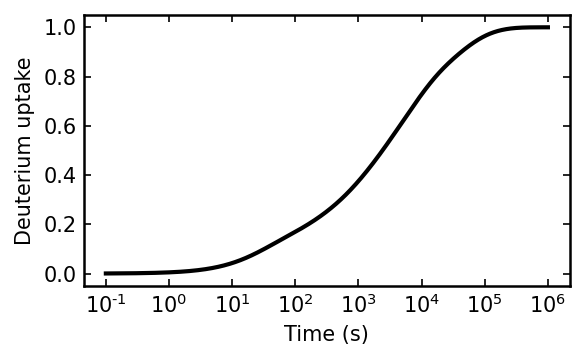

In [39]:
# now plot an uptake curve with the PFs

times = np.logspace(np.log10(0.1), np.log10(1e6), 1000)
kint = np.array(df['kint'])*100 # roughly corrected from pH 5.4 to 7.4
PFs = np.array(df['PF'])
uptakes = [np.mean(1-np.exp(-kint*t/PFs)) for t in times]
uptakes2 = [np.mean(1-np.exp(-kint*t/(PFs*0.5))) for t in times]

plt.figure(figsize = (4,2.5))
plt.plot(times, uptakes, color = 'black')
plt.xlabel('Time (s)')
plt.ylabel('Deuterium uptake')
plt.xscale('log')
plt.xticks(ticks=[1e-1,1e0,1e1,1e2,1e3,1e4,1e5,1e6])
plt.grid(False)
plt.tight_layout()
plt.savefig('example_uptake_curve_from_PF.png')

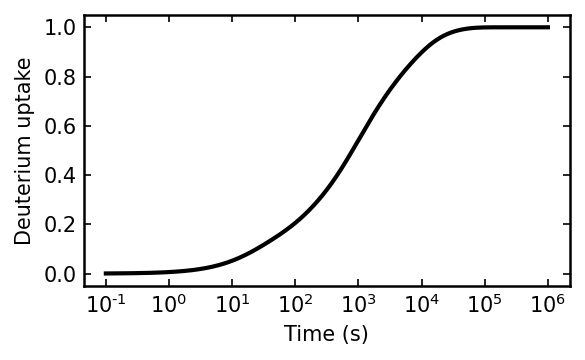

In [55]:
# now plot an uptake curve with the PFs

pep_df = df[df['Model_residue']>22][:-1] # peptide of the c-terminal helix

times = np.logspace(np.log10(0.1), np.log10(1e6), 1000)
kint = np.array(pep_df['kint'])*100 # roughly corrected from pH 5.4 to 7.4
PFs = np.array(pep_df['PF'])
uptakes = [np.mean(1-np.exp(-kint*t/PFs)) for t in times]
uptakes2 = [np.mean(1-np.exp(-kint*t/(PFs*0.5))) for t in times]

plt.figure(figsize = (4,2.5))
plt.plot(times, uptakes, color = 'black')
plt.xlabel('Time (s)')
plt.ylabel('Deuterium uptake')
plt.xscale('log')
plt.xticks(ticks=[1e-1,1e0,1e1,1e2,1e3,1e4,1e5,1e6])
plt.grid(False)
plt.tight_layout()
plt.savefig('example_uptake_curve_from_PF_cterm_peptide.png')

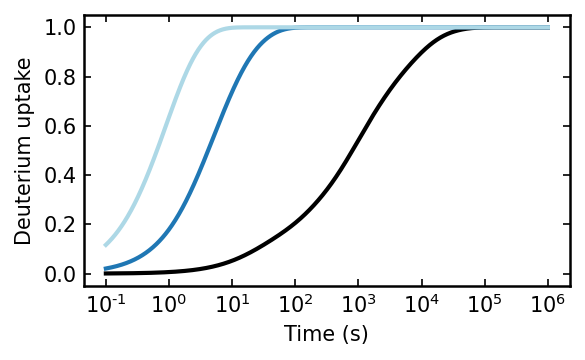

In [56]:
# now plot an uptake curve with the PFs with local unfolding

p_unf = 0.05  # 5%
target_pf = 1 / p_unf  
p_unf2 = 0.50  # 50%
target_pf2 = 1 / p_unf2  

df = pd.read_csv('../../EXP_DATA/PF_Nguyen_2018/HP36.csv')[:-1]
pep_df = df[df['Model_residue'] > 22].copy()  # peptide of the c-terminal helix
pep_df2 = df[df['Model_residue'] > 22].copy()  # peptide of the c-terminal helix

# scale PFs in log space so:
# - minimum PF becomes 1
# - the N->C trend / relative variation on the log scale is preserved
# - mean PF is ~10
logpf = np.log10(pep_df['PF'].values)
logpf = logpf - np.min(logpf)   # set minimum to PF = 1
logpf2 = np.log10(pep_df2['PF'].values)
logpf2 = logpf2 - np.min(logpf2)   # set minimum to PF = 1

alphas = np.linspace(0, 10, 10000)
means = np.array([np.mean(10**(a * logpf)) for a in alphas])
alpha = alphas[np.argmin(np.abs(means - target_pf))]
alphas2 = np.linspace(0, 10, 10000)
means2 = np.array([np.mean(10**(a * logpf2)) for a in alphas2])
alpha2 = alphas2[np.argmin(np.abs(means2 - target_pf2))]

pep_df['PF_scaled'] = 10**(alpha * logpf)
pep_df2['PF_scaled'] = 10**(alpha2 * logpf2)

times = np.logspace(np.log10(0.1), np.log10(1e6), 1000)
kint = np.array(pep_df['kint'])*100 # roughly corrected from pH 5.4 to 7.4
PFs = np.array(pep_df['PF'])
PFs2 = np.array(pep_df['PF_scaled'])
PFs3 = np.array(pep_df2['PF_scaled'])
uptakes = [np.mean(1-np.exp(-kint*t/PFs)) for t in times]
uptakes2 = [np.mean(1-np.exp(-kint*t/(PFs2*0.5))) for t in times]
uptakes3 = [np.mean(1-np.exp(-kint*t/(PFs3*0.5))) for t in times]

plt.figure(figsize = (4,2.5))
plt.plot(times, uptakes, color = 'black')
plt.plot(times, uptakes2, color = 'tab:blue')
plt.plot(times, uptakes3, color = 'lightblue')
plt.xlabel('Time (s)')
plt.ylabel('Deuterium uptake')
plt.xscale('log')
plt.xticks(ticks=[1e-1,1e0,1e1,1e2,1e3,1e4,1e5,1e6])
plt.grid(False)
plt.tight_layout()
plt.savefig('example_uptake_curve_from_PF_cterm_peptide_two_unf.png')

In [54]:
kint

array([0.25275171, 0.74587002, 1.59463906, 1.91717596, 5.1601218 ,
       0.57898786, 0.59247422, 1.26666705, 1.4178848 , 1.1072954 ,
       1.29618286, 0.40991307, 0.0060339 ])